# Exercice 12 — Softmax Regression *from scratch*

**Hands-On Machine Learning, chapitre 4, exercice 12**

> *Implement Batch Gradient Descent with early stopping for Softmax Regression without using Scikit-Learn, only NumPy. Use it on a classification task such as the iris dataset.*

L'objectif : écrire de A à Z, en NumPy pur, le GLM de la loi multinomiale vu en B15. Pas de `LogisticRegression`, pas de `SGDClassifier` — Scikit-Learn ne sert ici qu'à charger le jeu de données.

## Comment utiliser ce notebook

Le notebook alterne trois types de cellules :

| Type | Ce que tu fais |
|---|---|
| **Rappel** (markdown) | tu lis — la formule dont tu as besoin pour l'entraînement qui suit |
| **Entraînement $n$** (code) | tu écris le code à la place du `...` |
| **Vérification** (code) | tu exécutes telle quelle — elle teste ton code et te dit ce qui cloche |

Les corrigés sont tout à la fin, dans une section séparée. Va les voir si tu bloques plus de dix minutes sur un entraînement : l'objectif est de comprendre la mécanique, pas de souffrir.

## Notations

Ce notebook suit celles de HOML, qui ne sont pas celles de CS229 :

| | HOML (ici) | CS229 (tes notes) |
|---|---|---|
| nombre d'exemples | $m$ | $n$ |
| nombre de features | $n$ | $d$ |
| nombre de classes | $K$ | $k$ |

Dans le code, `n_inputs` $= n+1$ (features + biais) et `n_outputs` $= K$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (7, 4.5)

---
## Les données

On prend l'iris avec deux features seulement — longueur et largeur du pétale — pour pouvoir dessiner les frontières de décision à la fin. Trois espèces, donc $K = 3$ classes.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target.values

print("X :", X.shape, "  y :", y.shape)
print("classes :", iris.target_names)
print("5 premières lignes :")
print(X[:5])
print("étiquettes correspondantes :", y[:5])

X : (150, 2)   y : (150,)
classes : ['setosa' 'versicolor' 'virginica']
5 premières lignes :
[[1.4 0.2]
 [1.4 0.2]
 [1.3 0.2]
 [1.5 0.2]
 [1.4 0.2]]
étiquettes correspondantes : [0 0 0 0 0]


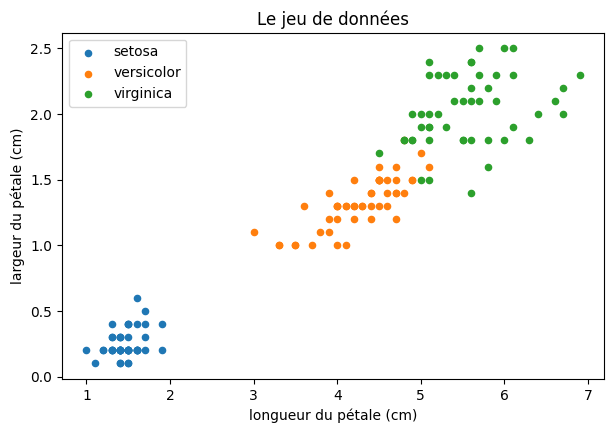

In [3]:
for classe, nom in enumerate(iris.target_names):
    plt.scatter(X[y == classe, 0], X[y == classe, 1], label=nom, s=20)
plt.xlabel("longueur du pétale (cm)")
plt.ylabel("largeur du pétale (cm)")
plt.legend()
plt.title("Le jeu de données")
plt.show()

In [4]:
len(X[0:5,0])

5

---
## Entraînement 1 — Le découpage train / validation / test

**Rappel.** Trois jeux, trois rôles distincts :

- **train** (60 %) — sert à calculer les gradients et à bouger $\Theta$.
- **validation** (20 %) — sert à décider *quand s'arrêter* (early stopping) et à régler les hyperparamètres. Le modèle ne s'entraîne jamais dessus, mais on s'en sert pour prendre des décisions, donc il est un peu « contaminé ».
- **test** (20 %) — on n'y touche qu'une seule fois, tout à la fin, pour annoncer un chiffre honnête.

Il faut **mélanger avant de couper** : dans l'iris, les étiquettes sont rangées dans l'ordre (50 zéros, 50 uns, 50 deux). Couper sans mélanger donnerait un jeu de test composé uniquement de la classe 2.

Écris la fonction. `rng.permutation(p)` te rend les entiers de 0 à $p-1$ dans un ordre aléatoire.

In [8]:
def split_data(X, y, test_ratio=0.2, validation_ratio=0.2, seed=42):
    '''Découpe X et y en trois jeux, après mélange.

    Retourne : X_train, y_train, X_valid, y_valid, X_test, y_test
    '''
    rng = np.random.default_rng(seed)

    # ENTRAÎNEMENT 1
    # 1. calcule les tailles des trois jeux à partir des ratios (int() pour arrondir)
    size = len(X)
    
    n_valid = int(size * validation_ratio)
    n_test = int(size * test_ratio)
    n_train = size - n_test - n_valid

    assert n_train + n_test + n_valid ==size, "Somme des trois split pas de la même taille que le set de base X"
    
    # 2. tire une permutation des indices
    random_id=rng.permutation(size)
    X_shuffled= X[random_id]
    y_shuffled = y[random_id]
    
    # 3. découpe X et y avec les trois tranches d'indices
    

    
    X_train = X_shuffled[:n_train]
    y_train = y_shuffled[:n_train]
    X_valid = X_shuffled[n_train:n_train+n_valid]
    y_valid = y_shuffled[n_train:n_train+n_valid]
    X_test = X_shuffled[n_train+n_valid:]
    y_test = y_shuffled[n_train+n_valid:]
    
    return X_train, y_train, X_valid, y_valid, X_test, y_test


X_train, y_train, X_valid, y_valid, X_test, y_test = split_data(X, y)

In [9]:
# Diagnostic
print("forme   :", y_test.shape, "  (attendu : (30,) )")
print("dtype   :", y_test.dtype, "  (attendu : int)")
print("contenu :", y_test[:5])

forme   : (30,)   (attendu : (30,) )
dtype   : int64   (attendu : int)
contenu : [2 0 0 2 2]


In [10]:
# Vérification
assert len(X_train) == 90 and len(X_valid) == 30 and len(X_test) == 30, \
    f"tailles attendues 90/30/30, obtenues {len(X_train)}/{len(X_valid)}/{len(X_test)}"
assert len(X_train) == len(y_train), "X_train et y_train n'ont pas la même longueur"
assert set(np.unique(y_test)) == {0, 1, 2}, "le jeu de test ne contient pas les 3 classes : as-tu mélangé ?"
print("OK — répartition des classes dans le train :", np.bincount(y_train))

OK — répartition des classes dans le train : [27 36 27]


---
## Entraînement 2 — Le one-hot encoding

**Rappel (B15-6).** Le modèle ne sort pas une étiquette, il sort **un vecteur de $K$ probabilités**. Pour comparer sa sortie à la vérité, il faut que la vérité ait la même forme. On transforme donc chaque étiquette en vecteur indicateur :

$$2 \ \longmapsto \ \begin{pmatrix} 0 & 0 & 1 \end{pmatrix}$$

C'est exactement le $T(y)$ de la famille exponentielle, à ceci près qu'en pratique on garde les $K$ composantes au lieu de $K-1$ (plus simple à coder, et la régularisation lèvera l'ambiguïté de la surparamétrisation).

Deux pistes : construire une matrice de zéros puis allumer la bonne case avec de l'indexation avancée, ou te servir de `np.eye`.

In [11]:
np.unique(y)

array([0, 1, 2])

In [14]:
def to_one_hot(y, n_classes=None):
    '''Transforme un vecteur d'étiquettes (m,) en matrice (m, n_classes) de 0 et de 1.'''
    if n_classes is None:
        n_classes = y.max() + 1

    # ENTRAÎNEMENT 2
    m = len(y)
    etiquettes = np.unique(y)
    n_classes=len(etiquettes)
    m_onehot=np.zeros((m, n_classes))
    m_onehot[:,y] = 1


Y_train_one_hot = to_one_hot(y_train)
Y_valid_one_hot = to_one_hot(y_valid)
Y_test_one_hot = to_one_hot(y_test)

In [15]:
# Vérification
assert Y_train_one_hot.shape == (90, 3), f"forme attendue (90, 3), obtenue {Y_train_one_hot.shape}"
assert np.all(Y_train_one_hot.sum(axis=1) == 1), "chaque ligne doit contenir exactement un 1"
assert np.all(Y_train_one_hot.argmax(axis=1) == y_train), "le 1 n'est pas dans la bonne colonne"
print("OK")
print("étiquettes  :", y_train[:4])
print("one-hot     :")
print(Y_train_one_hot[:4])

AttributeError: 'NoneType' object has no attribute 'shape'

---
## Entraînement 3 — Mise à l'échelle et ajout du biais

**Rappel.** Deux opérations, pour deux raisons différentes.

**La mise à l'échelle** (standardisation) : on centre et on réduit chaque feature,

$$x_{j}^{\text{scaled}} = \frac{x_{j} - \mu_{j}}{\sigma_{j}}$$

Sans ça, une feature qui varie de 1 à 7 et une autre de 0,1 à 2,5 donnent un bol très allongé, dans lequel la descente de gradient zigzague interminablement.

**Piège classique** : $\mu$ et $\sigma$ se calculent **sur le train uniquement**, puis s'appliquent aux trois jeux. Les calculer sur l'ensemble des données ferait fuiter de l'information du test vers l'entraînement.

**L'ajout du biais** : on colle une colonne de 1 pour que $\theta_{0}$ ait un siège, exactement comme `add_dummy_feature` du chapitre. `np.c_` concatène des colonnes.

In [ ]:
# ENTRAÎNEMENT 3a — calcule la moyenne et l'écart-type SUR LE TRAIN, puis standardise les trois jeux
mean = ...
std = ...

X_train_scaled = ...
X_valid_scaled = ...
X_test_scaled = ...


def add_bias(X):
    '''Ajoute une colonne de 1 à gauche de X.'''
    # ENTRAÎNEMENT 3b
    ...


X_train_b = add_bias(X_train_scaled)
X_valid_b = add_bias(X_valid_scaled)
X_test_b = add_bias(X_test_scaled)

In [ ]:
# Vérification
assert X_train_b.shape == (90, 3), f"forme attendue (90, 3), obtenue {X_train_b.shape}"
assert np.allclose(X_train_b[:, 0], 1), "la première colonne doit être pleine de 1"
assert np.allclose(X_train_b[:, 1:].mean(axis=0), 0, atol=1e-10), "le train n'est pas centré"
assert np.allclose(X_train_b[:, 1:].std(axis=0), 1, atol=1e-10), "le train n'est pas réduit"
assert not np.allclose(X_test_b[:, 1:].mean(axis=0), 0, atol=1e-3), \
    "le test est centré sur lui-même : tu as recalculé mean/std dessus au lieu de réutiliser ceux du train"
print("OK — moyenne du test après scaling :", X_test_b[:, 1:].mean(axis=0).round(3))

---
## Entraînement 4 — La fonction softmax

**Rappel (le cœur du modèle).** Le modèle calcule d'abord un score brut par classe, le *logit* :

$$s_{k}(x) = \theta^{(k)\top}x$$

puis transforme ces $K$ scores en probabilités :

$$\hat{p}_{k} = \sigma(\mathbf{s}(x))_{k} = \frac{\exp\left(s_{k}(x)\right)}{\sum_{j=1}^{K}\exp\left(s_{j}(x)\right)}$$

Exponentielle pour rendre tout positif, division par la somme pour que le total fasse 1.

**Le piège numérique.** `np.exp(800)` déborde et renvoie `inf`, puis `inf / inf` donne `nan`. Or la softmax est **insensible à un décalage global** : ajouter la même constante à tous les logits ne change rien au résultat (le facteur se simplifie entre le haut et le bas). On soustrait donc le maximum de chaque ligne avant d'exponentier — le plus grand exposant vaut alors 0, et tout tient.

Attention à `axis=1` et `keepdims=True` : on travaille ligne par ligne, un exemple à la fois.

In [ ]:
def softmax(logits):
    '''logits : (m, K) -> probabilités (m, K), chaque ligne sommant à 1.'''
    # ENTRAÎNEMENT 4
    # 1. soustrais le max de chaque ligne (stabilité numérique)
    # 2. exponentie
    # 3. divise par la somme de chaque ligne
    ...

In [ ]:
# Vérification
test_logits = np.array([[1.0, 2.0, 3.0], [0.0, 0.0, 0.0]])
P = softmax(test_logits)
assert P.shape == (2, 3), f"forme attendue (2, 3), obtenue {P.shape}"
assert np.allclose(P.sum(axis=1), 1), "chaque ligne doit sommer à 1"
assert np.allclose(P[1], 1/3), "trois logits égaux doivent donner trois probabilités égales"
assert P[0, 2] > P[0, 1] > P[0, 0], "le plus grand logit doit donner la plus grande probabilité"
assert np.all(np.isfinite(softmax(np.array([[1000.0, 999.0, 1.0]])))), \
    "débordement : tu n'as pas soustrait le maximum"
assert np.allclose(softmax(test_logits), softmax(test_logits + 100)), \
    "la softmax doit être insensible à un décalage global"
print("OK")
print(P)

---
## Entraînement 5 — La cross-entropy loss

**Rappel.** C'est l'opposé de la log-vraisemblance de la multinomiale — maximiser la vraisemblance et minimiser la cross-entropy sont le même geste.

$$J(\Theta) = -\frac{1}{m}\sum_{i=1}^{m}\sum_{k=1}^{K} y_{k}^{(i)}\log\left(\hat{p}_{k}^{(i)}\right)$$

Lis-la comme ceci : le one-hot $y^{(i)}$ éteint toutes les classes sauf la bonne, donc pour chaque exemple il ne reste que $-\log(\text{probabilité attribuée à la bonne classe})$. Si le modèle a mis 0,99 sur la bonne classe, le coût est $-\log(0{,}99) \approx 0{,}01$ : presque rien. S'il a mis 0,01, le coût est $-\log(0{,}01) \approx 4{,}6$ : salé. **La loss punit la confiance mal placée.**

**Un détail qui plante** : si une probabilité tombe exactement à 0, `np.log(0)` renvoie `-inf`. On ajoute donc un $\varepsilon$ minuscule.

In [ ]:
def cross_entropy(Y_proba, Y_one_hot, epsilon=1e-7):
    '''Coût moyen sur les m exemples.'''
    # ENTRAÎNEMENT 5
    ...

In [ ]:
# Vérification
Y_vrai = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])
parfait = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])
hesitant = np.full((2, 3), 1/3)
assert cross_entropy(parfait, Y_vrai) < 1e-5, "une prédiction parfaite doit coûter ~0"
assert abs(cross_entropy(hesitant, Y_vrai) - np.log(3)) < 1e-4, \
    "une prédiction totalement hésitante doit coûter log(3) ≈ 1.0986"
assert np.isfinite(cross_entropy(np.array([[0.0, 1.0, 0.0]]), np.array([[1.0, 0.0, 0.0]]))), \
    "log(0) : as-tu ajouté epsilon ?"
print("OK")
print("coût d'une prédiction parfaite  :", round(cross_entropy(parfait, Y_vrai), 6))
print("coût d'une prédiction hésitante :", round(cross_entropy(hesitant, Y_vrai), 6))

---
## Entraînement 6 — Le gradient

**Rappel.** Le résultat le plus satisfaisant du chapitre — le gradient par rapport aux paramètres de la classe $k$ vaut :

$$\nabla_{\theta^{(k)}}\,J(\Theta) = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{p}_{k}^{(i)} - y_{k}^{(i)}\right)x^{(i)}$$

C'est encore et toujours **(ce qu'on a répondu $-$ ce qu'il fallait répondre) $\times$ $x$**, exactement comme en régression linéaire et en régression logistique. C'est la signature de tous les GLM à canonical response function.

En vectorisé, les $K$ colonnes se calculent d'un coup :

$$\nabla_{\Theta}J = \frac{1}{m}X^{\top}\left(\hat{P} - Y\right)$$

Vérifie les formes : $X^{\top} \in \mathbb{R}^{(n+1) \times m}$, $(\hat{P} - Y) \in \mathbb{R}^{m \times K}$, donc le gradient est en $\mathbb{R}^{(n+1) \times K}$ — la même forme que $\Theta$. Toujours la même règle de survie.

In [ ]:
def gradients(X, Y_proba, Y_one_hot):
    '''Retourne le gradient, de même forme que Theta : (n_inputs, n_outputs).'''
    # ENTRAÎNEMENT 6
    ...

In [ ]:
# Vérification par gradient numérique : on compare ta formule à la pente mesurée
# en bougeant chaque paramètre d'un cheveu. Si les deux coïncident, ta dérivation est juste.
def gradients_numeriques(X, Y_one_hot, Theta, eps=1e-5):
    grads = np.zeros_like(Theta)
    for i in range(Theta.shape[0]):
        for j in range(Theta.shape[1]):
            T_plus, T_moins = Theta.copy(), Theta.copy()
            T_plus[i, j] += eps
            T_moins[i, j] -= eps
            J_plus = cross_entropy(softmax(X @ T_plus), Y_one_hot)
            J_moins = cross_entropy(softmax(X @ T_moins), Y_one_hot)
            grads[i, j] = (J_plus - J_moins) / (2 * eps)
    return grads


Theta_test = np.random.default_rng(0).normal(size=(3, 3))
g_analytique = gradients(X_train_b, softmax(X_train_b @ Theta_test), Y_train_one_hot)
g_numerique = gradients_numeriques(X_train_b, Y_train_one_hot, Theta_test)

assert g_analytique.shape == Theta_test.shape, \
    f"le gradient doit avoir la forme de Theta {Theta_test.shape}, il a {g_analytique.shape}"
assert np.allclose(g_analytique, g_numerique, atol=1e-5), \
    f"écart avec le gradient numérique :\n{np.abs(g_analytique - g_numerique)}"
print("OK — formule analytique et pente mesurée coïncident")
print(g_analytique)

---
## Entraînement 7 — La boucle de batch gradient descent

**Rappel.** *Batch* veut dire : tout le jeu d'entraînement à chaque pas. Un pas se déroule en quatre temps.

1. **Forward** — calculer les logits $X\Theta$, puis les probabilités.
2. **Mesurer** — la loss (seulement pour l'affichage, elle n'intervient pas dans le calcul).
3. **Backward** — le gradient.
4. **Mettre à jour** — $\Theta \leftarrow \Theta - \eta\,\nabla_{\Theta}J$.

Initialise $\Theta$ au hasard : avec des zéros partout, toutes les classes resteraient symétriques et le modèle n'apprendrait rien de distinct.

In [ ]:
n_inputs = X_train_b.shape[1]      # 2 features + le biais
n_outputs = len(np.unique(y_train))  # 3 classes
eta = 0.5
n_epochs = 5001

rng = np.random.default_rng(42)
Theta = rng.normal(size=(n_inputs, n_outputs))

historique = []

for epoch in range(n_epochs):
    # ENTRAÎNEMENT 7
    # 1. logits puis probabilités sur le train
    # 2. gradient
    # 3. mise à jour de Theta
    ...

    if epoch % 500 == 0:
        loss = cross_entropy(Y_proba, Y_train_one_hot)
        historique.append((epoch, loss))
        print(f"epoch {epoch:5d}   loss {loss:.5f}")

In [ ]:
# Vérification
Y_proba_valid = softmax(X_valid_b @ Theta)
accuracy = (Y_proba_valid.argmax(axis=1) == y_valid).mean()
assert historique[-1][1] < historique[0][1], "la loss n'a pas baissé : vérifie le signe de la mise à jour"
assert accuracy > 0.9, f"accuracy de validation trop basse : {accuracy:.3f}"
print(f"OK — accuracy sur la validation : {accuracy:.1%}")

epochs, losses = zip(*historique)
plt.plot(epochs, losses)
plt.xlabel("epoch"); plt.ylabel("cross-entropy (train)")
plt.title("La descente"); plt.grid(alpha=0.3); plt.show()

---
## Entraînement 8 — La régularisation $\ell_{2}$

**Rappel.** On ajoute au coût une pénalité sur la taille des paramètres :

$$J_{\text{reg}}(\Theta) = J(\Theta) + \frac{\alpha}{2}\sum_{j=1}^{n}\sum_{k=1}^{K}\left(\theta_{j}^{(k)}\right)^{2}$$

Pourquoi ? Des paramètres énormes produisent des logits énormes, donc des probabilités de 0,9999 : un modèle arrogant, qui colle au bruit du train et se plante sur ce qu'il n'a jamais vu. La pénalité le force à rester modeste.

Elle règle aussi la surparamétrisation dont on parlait : avec $K$ vecteurs au lieu de $K-1$, plusieurs $\Theta$ décrivent le même modèle ; la pénalité tranche en choisissant celui de plus petite norme.

**Deux détails qui comptent :**

- **On ne régularise jamais le biais** — d'où le $j$ qui commence à 1 dans la somme, et le `Theta[1:]` dans le code. Pénaliser $\theta_{0}$ reviendrait à forcer le modèle à prédire l'origine, ce qui n'a aucun sens.
- Le gradient de la pénalité est $\alpha\,\theta_{j}^{(k)}$, avec **une ligne de zéros en tête** pour laisser le biais tranquille. `np.r_` empile des lignes.

In [ ]:
alpha = 0.01
eta = 0.5
n_epochs = 5001

rng = np.random.default_rng(42)
Theta = rng.normal(size=(n_inputs, n_outputs))

for epoch in range(n_epochs):
    Y_proba = softmax(X_train_b @ Theta)

    # ENTRAÎNEMENT 8
    # 1. loss = cross-entropy + pénalité l2 (sans le biais)
    # 2. grads = gradient habituel + alpha * Theta, avec une ligne de zéros pour le biais
    # 3. mise à jour
    ...

    if epoch % 1000 == 0:
        print(f"epoch {epoch:5d}   loss régularisée {loss:.5f}")

In [ ]:
# Vérification
accuracy = (softmax(X_valid_b @ Theta).argmax(axis=1) == y_valid).mean()
assert accuracy > 0.9, f"accuracy de validation trop basse : {accuracy:.3f}"
print(f"OK — accuracy sur la validation : {accuracy:.1%}")
print("norme des poids (hors biais) :", round(np.sqrt((Theta[1:] ** 2).sum()), 3))
print("ligne du biais :", Theta[0].round(3))

---
## Entraînement 9 — L'early stopping

**Rappel.** On surveille la loss **sur la validation**, pas sur le train. Celle du train ne fait que descendre — elle ne te dira jamais d'arrêter. Celle de la validation descend, atteint un creux, puis remonte : à partir de ce creux, le modèle n'apprend plus le phénomène, il apprend le bruit du jeu d'entraînement.

L'algorithme :

- à chaque epoch, après la mise à jour, calculer la loss de validation ;
- si elle est meilleure que la meilleure connue, la retenir **et garder une copie de $\Theta$** ;
- sinon, arrêter et repartir de la copie sauvegardée.

**Le piège** : `best_Theta = Theta` ne copie rien du tout, les deux noms désignent le même tableau, qui sera écrasé au pas suivant. Il faut `Theta.copy()`.

Version volontairement stricte ici : on s'arrête à la première remontée. En pratique on tolère souvent quelques epochs de patience, parce que la courbe est bruitée.

In [ ]:
eta = 0.5
n_epochs = 50_001
alpha = 0.01
best_loss = np.inf

rng = np.random.default_rng(42)
Theta = rng.normal(size=(n_inputs, n_outputs))

for epoch in range(n_epochs):
    Y_proba = softmax(X_train_b @ Theta)
    grads = gradients(X_train_b, Y_proba, Y_train_one_hot)
    grads += np.r_[np.zeros([1, n_outputs]), alpha * Theta[1:]]
    Theta = Theta - eta * grads

    # ENTRAÎNEMENT 9
    # 1. probabilités sur la VALIDATION, puis loss régularisée
    # 2. si elle s'améliore : mémoriser best_loss, best_epoch et une COPIE de Theta
    # 3. sinon : afficher l'epoch d'arrêt et sortir de la boucle
    ...

    if epoch % 1000 == 0:
        print(f"epoch {epoch:5d}   loss validation {valid_loss:.5f}")

In [ ]:
# Vérification
assert "best_Theta" in dir(), "best_Theta n'existe pas"
assert best_loss < np.inf, "best_loss n'a jamais été mis à jour"
assert not np.shares_memory(best_Theta, Theta), \
    "best_Theta pointe sur le même tableau que Theta : il manque .copy()"
print(f"OK — arrêt retenu à l'epoch {best_epoch}, loss validation {best_loss:.5f}")

---
## Entraînement 10 — L'évaluation finale

On ouvre le jeu de test. Une seule fois.

L'accuracy, c'est la proportion de prédictions correctes — et la prédiction, c'est simplement la classe au `argmax` des probabilités.

In [ ]:
# ENTRAÎNEMENT 10 — calcule les probabilités sur le test avec best_Theta, puis l'accuracy
Y_proba_test = ...
y_pred = ...
accuracy_test = ...

print(f"accuracy sur le test : {accuracy_test:.1%}")

In [ ]:
# Vérification
assert accuracy_test > 0.85, f"accuracy de test suspecte : {accuracy_test:.3f}"
print("OK")

matrice = np.zeros((3, 3), dtype=int)
for vrai, predit in zip(y_test, y_pred):
    matrice[vrai, predit] += 1
print("\nMatrice de confusion (lignes = vrai, colonnes = prédit) :")
print(matrice)
print("\nclasses :", list(iris.target_names))

---
## Les frontières de décision

Rien à compléter ici — c'est la récompense. On couvre le plan d'une grille de points, on demande au modèle sa prédiction en chacun, et on colorie.

Note que les frontières sont **droites** : la softmax regression est un modèle linéaire. Chaque frontière entre deux classes est l'endroit où leurs deux logits s'égalisent, c'est-à-dire un hyperplan.

In [ ]:
x0, x1 = np.meshgrid(np.linspace(0, 8, 500), np.linspace(0, 3.5, 300))
X_grille = np.c_[x0.ravel(), x1.ravel()]
X_grille_b = add_bias((X_grille - mean) / std)

zz = softmax(X_grille_b @ best_Theta).argmax(axis=1).reshape(x0.shape)

plt.contourf(x0, x1, zz, cmap="Pastel2", levels=[-0.5, 0.5, 1.5, 2.5])
for classe, nom in enumerate(iris.target_names):
    plt.scatter(X_train[y_train == classe, 0], X_train[y_train == classe, 1],
                label=nom, s=22, edgecolor="k", linewidth=0.3)
plt.xlabel("longueur du pétale (cm)")
plt.ylabel("largeur du pétale (cm)")
plt.legend(loc="upper left")
plt.title("Frontières de décision de ta softmax regression")
plt.show()

---
## Pour aller plus loin

Quelques pistes, une fois le notebook terminé :

1. **Compare à Scikit-Learn.** `LogisticRegression(C=1/(alpha*len(X_train)))` doit donner une frontière très proche de la tienne. Si l'écart est grand, quelque chose cloche dans ta dérivation.
2. **Fais varier `alpha`** entre 0 et 10 et trace l'accuracy de validation. Tu verras le compromis biais-variance en direct.
3. **Fais varier `eta`.** À 0,01 la descente rampe ; vers 10 elle diverge. Trouve la frontière.
4. **Remplace le batch par du SGD** en tirant un exemple au hasard à chaque pas, et compare le nombre de pas et le temps de calcul nécessaires pour atteindre la même accuracy.
5. **Reprends les quatre features de l'iris** au lieu de deux. L'accuracy monte, mais on ne peut plus dessiner — c'est le prix.

---
# Corrigés

À consulter si tu bloques. Copie la cellule qui t'intéresse dans ton entraînement et continue.

### Entraînement 1 — découpage

```python
    total_size = len(X)
    test_size = int(total_size * test_ratio)
    validation_size = int(total_size * validation_ratio)
    train_size = total_size - test_size - validation_size

    perm = rng.permutation(total_size)
    idx_train = perm[:train_size]
    idx_valid = perm[train_size:train_size + validation_size]
    idx_test = perm[train_size + validation_size:]

    return (X[idx_train], y[idx_train],
            X[idx_valid], y[idx_valid],
            X[idx_test], y[idx_test])
```

### Entraînement 2 — one-hot

```python
    return np.eye(n_classes)[y]
```

Version explicite, si la ligne du dessus te paraît magique :

```python
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1
    return Y
```

### Entraînement 3 — scaling et biais

```python
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_scaled = (X_train - mean) / std
X_valid_scaled = (X_valid - mean) / std
X_test_scaled = (X_test - mean) / std


def add_bias(X):
    return np.c_[np.ones(len(X)), X]
```

### Entraînement 4 — softmax

```python
    z = logits - logits.max(axis=1, keepdims=True)
    exps = np.exp(z)
    return exps / exps.sum(axis=1, keepdims=True)
```

### Entraînement 5 — cross-entropy

```python
    return -np.mean(np.sum(Y_one_hot * np.log(Y_proba + epsilon), axis=1))
```

### Entraînement 6 — gradient

```python
    m = len(X)
    erreur = Y_proba - Y_one_hot
    return X.T @ erreur / m
```

### Entraînement 7 — boucle

```python
    logits = X_train_b @ Theta
    Y_proba = softmax(logits)
    grads = gradients(X_train_b, Y_proba, Y_train_one_hot)
    Theta = Theta - eta * grads
```

### Entraînement 8 — régularisation

```python
    loss = cross_entropy(Y_proba, Y_train_one_hot) + alpha / 2 * (Theta[1:] ** 2).sum()
    grads = gradients(X_train_b, Y_proba, Y_train_one_hot)
    grads += np.r_[np.zeros([1, n_outputs]), alpha * Theta[1:]]
    Theta = Theta - eta * grads
```

### Entraînement 9 — early stopping

```python
    Y_proba_valid = softmax(X_valid_b @ Theta)
    valid_loss = (cross_entropy(Y_proba_valid, Y_valid_one_hot)
                  + alpha / 2 * (Theta[1:] ** 2).sum())

    if valid_loss < best_loss:
        best_loss = valid_loss
        best_epoch = epoch
        best_Theta = Theta.copy()
    else:
        print(f"early stopping à l'epoch {epoch} — loss {valid_loss:.5f}")
        break
```

### Entraînement 10 — évaluation

```python
Y_proba_test = softmax(X_test_b @ best_Theta)
y_pred = Y_proba_test.argmax(axis=1)
accuracy_test = (y_pred == y_test).mean()
```